# Pad Masking Ablation: Tokenized Data + Eval Loss

This notebook compares two tokenized datasets from the same sampled input:
- masked labels (`pad -> -100`)
- unmasked labels (legacy `labels=input_ids`)

and connects that difference to short-run eval loss.

In [1]:
import json
from pathlib import Path

MASKED_PATH = Path('/tmp/tokenized_10langs_masked')
UNMASKED_PATH = Path('/tmp/tokenized_10langs_unmasked')
MASKED_RUN = Path('/tmp/cola_padmask_ablation_masked_v2')
UNMASKED_RUN = Path('/tmp/cola_padmask_ablation_unmasked_v2')

print('masked dataset exists:', MASKED_PATH.exists())
print('unmasked dataset exists:', UNMASKED_PATH.exists())
print('masked run exists:', MASKED_RUN.exists())
print('unmasked run exists:', UNMASKED_RUN.exists())

masked dataset exists: True
unmasked dataset exists: True
masked run exists: True
unmasked run exists: True


In [2]:
from datasets import load_from_disk

masked = load_from_disk(str(MASKED_PATH))
unmasked = load_from_disk(str(UNMASKED_PATH))

print('rows masked:', len(masked))
print('rows unmasked:', len(unmasked))
print('features:', masked.features)

rows masked: 256
rows unmasked: 256
features: {'language': Value('string'), 'split': Value('string'), 'input_ids': List(Value('int32')), 'attention_mask': List(Value('int8')), 'labels': List(Value('int64')), 'language_ids': Value('int64'), 'family_ids': Value('int64')}


$HOME/.conda/envs/merlin/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
# Verify only labels differ
diff_input = 0
diff_attention = 0
diff_labels = 0

for a, b in zip(masked, unmasked):
    if a['input_ids'] != b['input_ids']:
        diff_input += 1
    if a['attention_mask'] != b['attention_mask']:
        diff_attention += 1
    if a['labels'] != b['labels']:
        diff_labels += 1

print({'diff_input': diff_input, 'diff_attention': diff_attention, 'diff_labels': diff_labels})

{'diff_input': 0, 'diff_attention': 0, 'diff_labels': 175}


In [4]:
# Pad-label audit
def pad_label_stats(ds):
    total_pad = 0
    pad_not_ignored = 0
    total_tokens = 0
    for ex in ds:
        for m, y in zip(ex['attention_mask'], ex['labels']):
            total_tokens += 1
            if m == 0:
                total_pad += 1
                if y != -100:
                    pad_not_ignored += 1
    ratio = (pad_not_ignored / total_pad) if total_pad else 0.0
    return {
        'total_tokens': total_tokens,
        'pad_tokens': total_pad,
        'pad_labels_not_ignored': pad_not_ignored,
        'ratio': ratio,
    }

print('masked:', pad_label_stats(masked))
print('unmasked:', pad_label_stats(unmasked))

masked: {'total_tokens': 262144, 'pad_tokens': 111930, 'pad_labels_not_ignored': 0, 'ratio': 0.0}
unmasked: {'total_tokens': 262144, 'pad_tokens': 111930, 'pad_labels_not_ignored': 111930, 'ratio': 1.0}


In [5]:
# Show one concrete row with pad positions
example_idx = None
for i, (a, b) in enumerate(zip(masked, unmasked)):
    if a['labels'] != b['labels']:
        example_idx = i
        break

print('first differing row:', example_idx)

ex_m = masked[example_idx]
ex_u = unmasked[example_idx]
pad_positions = [j for j, m in enumerate(ex_m['attention_mask']) if m == 0]
print('num pad positions:', len(pad_positions))
print('first 20 pad positions:', pad_positions[:20])

rows = []
for j in pad_positions[:20]:
    rows.append({
        'pos': j,
        'input_id': ex_m['input_ids'][j],
        'masked_label': ex_m['labels'][j],
        'unmasked_label': ex_u['labels'][j],
    })

try:
    import pandas as pd
    display(pd.DataFrame(rows))
except Exception:
    print(rows)

first differing row: 1
num pad positions: 528
first 20 pad positions: [496, 497, 498, 499, 500, 501, 502, 503, 504, 505, 506, 507, 508, 509, 510, 511, 512, 513, 514, 515]


,pos,input_id,masked_label,unmasked_label
0,496,128001,-100,128001
1,497,128001,-100,128001
2,498,128001,-100,128001
3,499,128001,-100,128001
4,500,128001,-100,128001
5,501,128001,-100,128001
6,502,128001,-100,128001
7,503,128001,-100,128001
8,504,128001,-100,128001
9,505,128001,-100,128001


In [6]:
# Load final eval losses
with open(MASKED_RUN / 'eval_results.json', 'r', encoding='utf-8') as f:
    masked_eval = json.load(f)
with open(UNMASKED_RUN / 'eval_results.json', 'r', encoding='utf-8') as f:
    unmasked_eval = json.load(f)

print('masked final eval_loss:', masked_eval['eval_loss'])
print('unmasked final eval_loss:', unmasked_eval['eval_loss'])

masked final eval_loss: 2.7240467071533203
unmasked final eval_loss: 1.5301992893218994


In [7]:
# Parse eval-loss trajectory from trainer_state
def eval_curve(run_dir):
    with open(run_dir / 'trainer_state.json', 'r', encoding='utf-8') as f:
        state = json.load(f)
    points = []
    for item in state.get('log_history', []):
        if 'eval_loss' in item and 'step' in item:
            points.append((item['step'], item['eval_loss']))
    return points

masked_curve = eval_curve(MASKED_RUN)
unmasked_curve = eval_curve(UNMASKED_RUN)

print('masked curve:', masked_curve)
print('unmasked curve:', unmasked_curve)

masked curve: [(3, 2.795919179916382), (6, 2.7451610565185547), (9, 2.7240467071533203)]
unmasked curve: [(3, 1.642228126525879), (6, 1.5458487272262573), (9, 1.5301992893218994)]


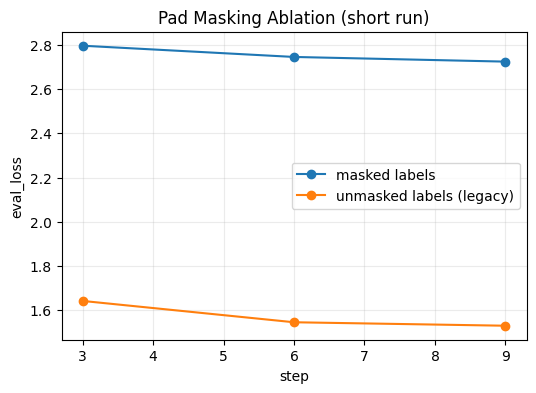

In [8]:
# Optional quick plot
try:
    import matplotlib.pyplot as plt
    mx, my = zip(*masked_curve)
    ux, uy = zip(*unmasked_curve)

    plt.figure(figsize=(6,4))
    plt.plot(mx, my, marker='o', label='masked labels')
    plt.plot(ux, uy, marker='o', label='unmasked labels (legacy)')
    plt.xlabel('step')
    plt.ylabel('eval_loss')
    plt.title('Pad Masking Ablation (short run)')
    plt.grid(True, alpha=0.25)
    plt.legend()
    plt.show()
except Exception as e:
    print('plot skipped:', e)

Variant 1 — ❌ Wrong (pads included in loss) → ~1.7 loss
```text
input_ids:      [101, 102,   0,   0,   0,   0]
attention_mask: [  1,   1,   0,   0,   0,   0]
labels:         [101, 102,   0,   0,   0,   0]
```

Model is trained to predict `<pad>` → trivial → loss collapses.

Variant 2 — ✅ Correct (pads masked) → ~2.7 loss
```text
input_ids:      [101, 102,   0,   0,   0,   0]
attention_mask: [  1,   1,   0,   0,   0,   0]
labels:         [101, 102, -100, -100, -100, -100]
```

Loss computed only on real tokens → meaningful language modeling.

Variant 3 — ❌ Pathological (same bug on hard multilingual data) → ~4.0 loss
```text
input_ids:      [101, 205, 917, 311,  44,   0]
attention_mask: [  1,   1,   1,   1,   1,   0]
labels:         [101, 205, 917, 311,  44,   0]
```

Padding dominates gradients on high-entropy data → unstable, high loss.
